In [19]:

import numpy as np
import torch
torch.set_default_device("cuda")

import numpy as np
import matgl
from ase.build import molecule
from ase.io import read
from matgl.ext.ase import Atoms2Graph, PESCalculator
import matplotlib
# matplotlib.use('TkAgg')  # Use a non-interactive backend
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
%matplotlib inline



In [20]:
def create_sparse_adjacency_matrix(atoms, cutoff, element_types):
    graph, lattice, state_attr_default = Atoms2Graph(element_types, cutoff).get_graph(atoms)
    sources, destinations = graph.edges()
    num_nodes = max(sources.max(), destinations.max()) + 1
    adjacency_matrix_sparse = coo_matrix((np.ones(len(sources)), (sources.cpu().numpy(), destinations.cpu().numpy())), shape=(num_nodes, num_nodes)).tocsr()
    return adjacency_matrix_sparse, num_nodes, graph.edges()
    

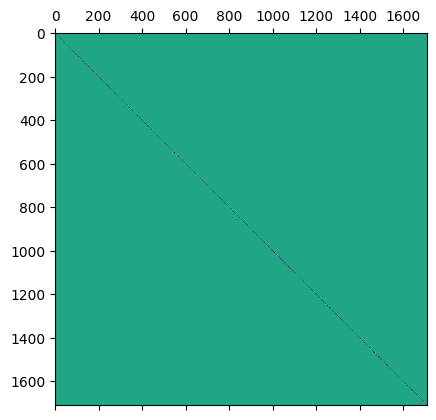

In [22]:
pot = matgl.load_model("../pretrained_models/TensorNet-ANI-1x-Subset-PES")
n_layers = len(pot.model.layers)
pot.calc_hessian = True
# atoms = read('/h/28/lucahiede/Projects/sparse_hessian_ff/data/AT-AT-CG-CG_random_point.xyz')
atoms = read('/h/28/lucahiede/Projects/sparse_hessian_ff/data/water_cluster/190.xyz')

element_types = pot.model.element_types
cutoff = pot.model.cutoff 


adjacency_matrix_sparse, n, edges = create_sparse_adjacency_matrix(atoms, cutoff, element_types)

# Convert to dense matrix
adjacency_matrix = adjacency_matrix_sparse.toarray()
sparsity_pattern = np.linalg.matrix_power(adjacency_matrix, n_layers)
sparsity_pattern = sparsity_pattern != 0

calc = PESCalculator(pot, hessian_algorithm="naive")
calc.calculate(atoms, properties=['hessian'])
hessian = np.array(calc.results['hessian'])
plt.matshow(hessian)
plt.show()

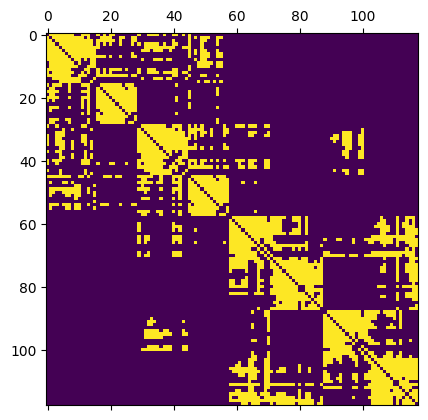

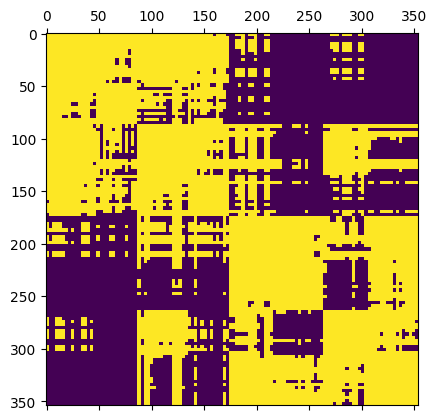

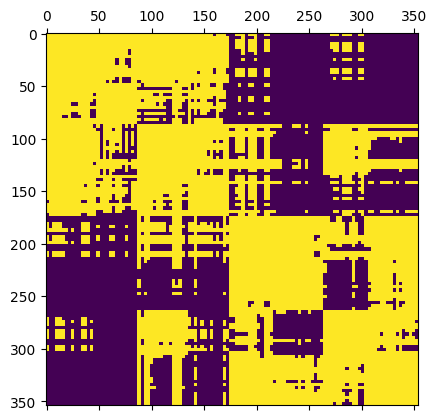

In [12]:
plt.matshow(adjacency_matrix, cmap='viridis')
plt.show()
sparsity_pattern = sparsity_pattern != 0
plt.matshow(np.kron(sparsity_pattern, np.ones((3,3))), cmap='viridis')
plt.show()
hessian_pattern = hessian != 0
plt.matshow(hessian_pattern, cmap='viridis')
plt.show()

In [67]:
print((np.abs(hessian) > 1e-3).mean())
print((hessian_pattern).mean())

0.3618532350218647
0.546394714162597


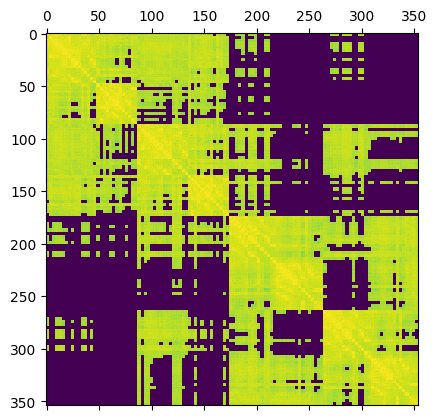

In [5]:
plt.matshow(np.abs(hessian)**0.01)
plt.show()